# Lesson 13 pre-class prep: Reprojecting and merging

Before class, make sure you can import the data we will use in [lesson 13](https://meds-eds-220.github.io/MEDS-eds-220-course/book/chapters/lesson-12-merge-data/lesson-12-merge-data.html). Run the four code cells in this notebook. If they all run without errors, you are ready for class!

## About the data

We will use three datasets:

1. **Arctic communities**: a GeoJSON file with the [list of Arctic communities and their location](https://search.dataone.org/view/doi%3A10.18739%2FA28S4JQ80), created by the [Alaska Native Tribal Health Consortium](https://www.anthc.org). We will read it directly from its URL, so you don't need to download it.

2. **Countries**: [Natural Earth's medium-scale cultural boundaries data for countries (1:50m)](https://www.naturalearthdata.com/downloads/50m-cultural-vectors/). [Natural Earth](https://www.naturalearthdata.com) is a public domain dataset with free, ready-to-use data for creating maps. To download it:
    1. Go to the [Natural Earth 1:50m cultural vectors page](https://www.naturalearthdata.com/downloads/50m-cultural-vectors/).
    2. Under "Admin 0 – Countries", click on "Download countries".
    3. Unzip the file and move the `ne_50m_admin_0_countries` folder into a `data/` folder at the same level as this notebook.

3. **Country names**: a CSV with the country codes and names of the Arctic countries in the Arctic communities dataset. It was created for this lesson from the metadata of the Arctic communities dataset and the country names in Natural Earth's dataset. We will read it directly from its URL, so you don't need to download it.

Read the information about the datasets in the [lesson](https://meds-eds-220.github.io/MEDS-eds-220-course/book/chapters/lesson-12-merge-data/lesson-12-merge-data.html) before class.

## Import libraries

In [1]:
import os

import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

## Import countries shapefile

In [2]:
fp = os.path.join('data', 'ne_50m_admin_0_countries', 'ne_50m_admin_0_countries.shp')
countries = gpd.read_file(fp)

# Simplify column names
countries.columns = countries.columns.str.lower()

# Select columns for analysis
countries = countries[['admin', 'type', 'geometry']]

countries.head(3)

,admin,type,geometry
0,Zimbabwe,Sovereign country,"POLYGON ((31.28789 -22.40205, 31.19727 -22.344..."
1,Zambia,Sovereign country,"POLYGON ((30.39609 -15.64307, 30.25068 -15.643..."
2,Yemen,Sovereign country,"MULTIPOLYGON (((53.08564 16.64839, 52.58145 16..."


## Import Arctic communities data

In [3]:
URL = 'https://cn.dataone.org/cn/v2/resolve/urn%3Auuid%3Aed7718ae-fb0d-43dd-9270-fbfe80bfc7a4'
communities = gpd.read_file(URL)

communities.head(3)

,name,population,country,geoname-id,geometry
0,Udomlya,32373,RU,452949,POINT (34.99250 57.87944)
1,Valmiera,26963,LV,453754,POINT (25.42751 57.54108)
2,Ventspils,42644,LV,454310,POINT (21.57288 57.38988)


## Import country names CSV

In [4]:
URL = 'https://raw.githubusercontent.com/MEDS-eds-220/MEDS-eds-220-course/refs/heads/main/book/chapters/lesson-12-merge-data/country_names.csv'
country_names = pd.read_csv(URL)

country_names.head(3)

,country,admin
0,RU,Russia
1,LV,Latvia
2,EE,Estonia


<Axes: >

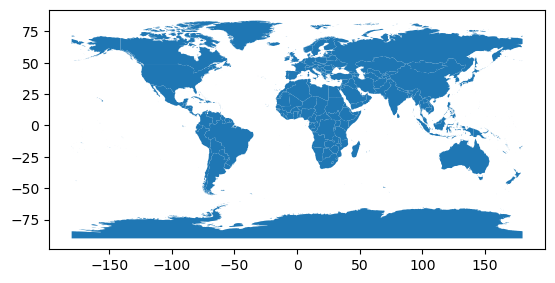

In [7]:
# Quick view
countries.plot()

In [ ]:
print(countries.crs)

EPSG:4326


In [9]:
# Verify that crs match
assert countries.crs == communities.crs

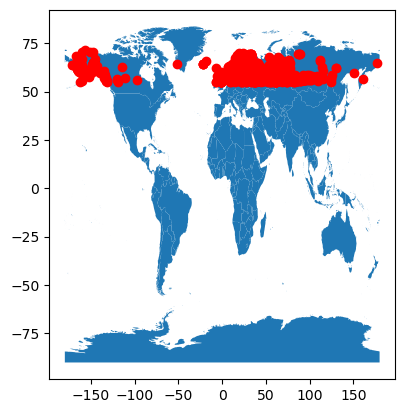

In [10]:
# Plot both datasets
fig, ax = plt.subplots()
countries.plot(ax=ax)
communities.plot(ax=ax, color='red')
plt.show()

## Arctic communities by country

We want to calculate the number of Arctic communities by country

In [12]:
# Create data frame with number of communities per country
n_comms = (communities.groupby('country')
                      .size()
                      .reset_index(name='n_communities'))
n_comms

,country,n_communities
0,AX,1
1,BY,8
2,CA,7
3,DK,72
4,EE,14
5,FI,98
6,FO,1
7,GB,96
8,GL,1
9,IS,5


Goal: merge the `n_comms` and the `counties` data frames.

To merge two data frames they need to have at least one column in common. Do they?

In [ ]:
common_columns = set(countries.columns).intersection(n_comms.columns)

# Check if there are any common columns
if len(common_columns) != 0:
    print(f"Common columns: {common_columns}")
else:
    print("No common columns")

# Function version
def check_common_columns(df1,df2):
    """Checks for columns in common between two specified DataFrames."""
    # Find common columns
    common_columns = set(df1.columns).intersection(df2.columns)    
    # Check if there are any common columns
    if len(common_columns) != 0:
        print(f"Common columns: {common_columns}")
    else:
        print("No common columns")

No common columns


In [18]:
check_common_columns(countries,n_comms)

No common columns


## Merging Data Frames

Syntax:

```{python}
output_df = pd.merge(left_df,
                     right_df, 
                     how = type_of_join, 
                     on = column_to_join)
```

In [19]:
# Merge
n_comms = pd.merge(n_comms,
                   country_names,
                   how='left',
                   on='country')
n_comms

,country,n_communities,admin
0,AX,1,Aland Islands
1,BY,8,Belarus
2,CA,7,Canada
3,DK,72,Denmark
4,EE,14,Estonia
5,FI,98,Finland
6,FO,1,Faroe Islands
7,GB,96,United Kingdom
8,GL,1,Greenland
9,IS,5,Iceland


In [20]:
# Confirm a common column now exists
check_common_columns(n_comms, countries)

Common columns: {'admin'}


### Check-In

Create a new variable named arctic_countries which is the result of an inner join between our countries and n_comms data frames. The inner join will merge the subset of rows that have matches in both the left table and the right table.

In [21]:
arctic_countries = pd.merge(n_comms,
                            countries,
                            how='inner',
                            on='admin')
arctic_countries

,country,n_communities,admin,type,geometry
0,BY,8,Belarus,Sovereign country,"POLYGON ((31.76338 52.10107, 31.57373 52.10811..."
1,CA,7,Canada,Sovereign country,"MULTIPOLYGON (((-132.65552 54.12749, -132.5640..."
2,DK,72,Denmark,Country,"MULTIPOLYGON (((12.56875 55.78506, 12.57119 55..."
3,EE,14,Estonia,Sovereign country,"MULTIPOLYGON (((27.35195 57.52812, 27.32656 57..."
4,FI,98,Finland,Country,"MULTIPOLYGON (((24.15547 65.80527, 24.04902 65..."
5,FO,1,Faroe Islands,Dependency,"MULTIPOLYGON (((-6.62319 61.80596, -6.64277 61..."
6,GB,96,United Kingdom,Country,"MULTIPOLYGON (((-2.66768 51.62300, -2.74214 51..."
7,GL,1,Greenland,Country,"MULTIPOLYGON (((-29.95288 83.56484, -28.99199 ..."
8,IS,5,Iceland,Sovereign country,"POLYGON ((-15.54312 66.22852, -15.42847 66.224..."
9,LT,26,Lithuania,Sovereign country,"MULTIPOLYGON (((20.95781 55.27891, 20.89980 55..."


## Reviewing results

In [22]:
print(f"Countries in n_comms: {len(n_comms)}")
print(f"Countries in arctic_countries: {len(arctic_countries)}")

Countries in n_comms: 16
Countries in arctic_countries: 15


In [23]:
# Countries in n_comms without a match in countries
n_comms[~n_comms['admin'].isin(countries['admin'])]

,country,n_communities,admin
0,AX,1,Aland Islands


In [24]:
# Search for Aland in countires - why didn't it match?
countries[countries['admin'].str.contains('Aland')]

,admin,type,geometry
168,Aland,Country,"MULTIPOLYGON (((19.98955 60.35117, 20.02021 60..."


In [25]:
# Fix Aland mismatch and re-merge
# Match the name used in the countries data
n_comms['admin'] = n_comms['admin'].replace('Aland Islands', 'Aland')

# Merge again
arctic_countries = countries.merge(n_comms,
                                   how='inner',
                                   on='admin')
print(f"Countries in arctic_countries: {len(arctic_countries)}")

Countries in arctic_countries: 16


In [26]:
# Indicator = True example
left = pd.DataFrame({'key': ['a', 'b', 'c'], 'x': [1, 2, 3]})
right = pd.DataFrame({'key': ['a', 'b', 'd'], 'y': [4, 5, 6]})

pd.merge(left, right, how='outer', on='key', indicator=True)

,key,x,y,_merge
0,a,1.0,4.0,both
1,b,2.0,5.0,both
2,c,3.0,NaN,left_only
3,d,NaN,6.0,right_only


## Choropleth Map

<Axes: >

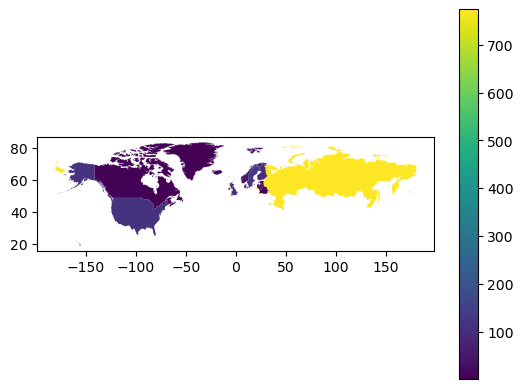

In [27]:
# Plot
arctic_countries.plot(column='n_communities',
                      legend=True)

## Reprojecting

**Reprojecting** means changing the coordinate reference system of your geospatial data. In our case, we will reproject the arctic_countries geodataframe to the CRS EPSG:3413. This CRS is a projected CRS, better suited for working with data from the Arctic region:

Syntax:

```{python}
updated_geodf = geodf.to_crs(new_crs)
```

In [28]:
# Reproject to CRS optimized for Arctic region
arctic_countries = arctic_countries.to_crs('epsg:3413')

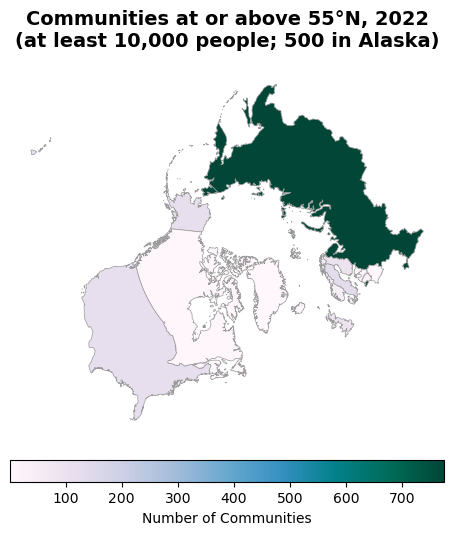

In [29]:
fig, ax = plt.subplots(figsize=(8, 6))

# Remove the axis for a cleaner map
ax.axis('off')

# Create choropleth map of communities
# Plot with refined color and edge style
arctic_countries.plot(
    ax=ax,
    column='n_communities',
    cmap='PuBuGn',
    legend=True,
    edgecolor="0.6",
    linewidth=0.5,
    legend_kwds={
        "shrink": 0.7,
        "label": "Number of Communities",
        "orientation": "horizontal",
        "pad": 0.05
    }
)

# Add title for better context
ax.set_title('Communities at or above 55°N, 2022\n(at least 10,000 people; 500 in Alaska)',
             fontsize=14, weight='bold', pad=15)

plt.show()